# Part 5:  Vibe-Coding Emerging Optimizers on CIFAR Classification 

As large language models (LLMs) reshape software engineering, we are entering a new era of AI-assisted programming where human creativity and machine execution merge. Instead of focusing on every low-level implementation detail, developers can prioritize **ideas, exploration, and iteration speed**, while the model handles much of the routine coding. This is the essence of [**vibe coding**](https://en.wikipedia.org/wiki/Vibe_coding?utm_source=chatgpt.com): coding by “vibes” and letting AI accelerate the path from concept to working system. In this homework, you will practice vibe coding by using AI assistants such as [ChatGPT](https://chat.openai.com), [Gemini](https://gemini.google.com/app), or [Claude](https://www.anthropic.com/claude-code) to help design and implement optimizers for CIFAR image classification.  

---

## 1. What is *Vibe Coding*? 

**Vibe coding** is a paradigm popularized by Andrej Karpathy in 2025. It emphasizes generating most of the code through LLMs while the human programmer acts as a **guide, tester, and refiner**. Instead of carefully reviewing every line, you iterate based on execution results, keeping the creative process at the center.  

Karpathy put it simply:  
> *“Fully giving in to the vibes, embracing exponentials, and forgetting that the code even exists.”*  

**Learn more :**
- [IBM: What is Vibe Coding?](https://www.ibm.com/think/topics/vibe-coding?utm_source=chatgpt.com)  
- [Replit Blog: What is Vibe Coding?](https://blog.replit.com/what-is-vibe-coding?utm_source=chatgpt.com)  

---

## 2. Objectives 

- Understand and implement **novel optimizers** (Muon, Scion, SODA).  
- Practice **vibe coding** as a workflow with LLMs.  
- Compare optimizer performance on **CIFAR-10** across Transformer and ResNet architectures.  
- Analyze results critically and reflect on the coding process.  

---

## 3. Task Overview 

You will implement and compare four optimizers on **CIFAR-10 classification** with two architectures: a **Transformer**  and a **ResNet** .  

- **Optimizers**: Muon , Scion , SODA , Adam (baseline)  
- **Models**: Transformer, ResNet  
- **Comparison metrics**: convergence speed, final test accuracy , training stability  

---

## 4. Optimizers to Implement 

### (1) Muon 
Muon applies **Newton–Schulz orthonormalization** to gradient updates of 2D weight matrices, making them invariant to input conditioning.  
References:  
- [Muon Blog (Keller Jordan)](https://kellerjordan.github.io/posts/muon/?utm_source=chatgpt.com)  
- [Deriving Muon (Jeremy Bernstein)](https://jeremybernste.in/writing/deriving-muon?utm_source=chatgpt.com)  
- [Muon GitHub Repo](https://github.com/KellerJordan/Muon?utm_source=chatgpt.com)  
- [Convergence Bound (arXiv)](https://arxiv.org/abs/2507.01598?utm_source=chatgpt.com)  

---

### (2) Scion 
Scion constrains updates differently for hidden vs input/output layers, using **spectral norm** for hidden layers and **ℓ∞ norm** for others. This improves stability and hyperparameter transfer.  
References:  
- [Scion Paper](https://arxiv.org/abs/2502.07529)  
- [Scion Official Code](https://github.com/LIONS-EPFL/scion)  

---

### (3) SODA 
SODA wraps a base optimizer with a theoretically grounded, initialization-centered **1/k weight-decay schedule**, motivating us to test whether it improves CIFAR-10 training without tuning weight decay.  
References:  
- [SODA Paper (arXiv)](https://arxiv.org/pdf/2605.11172)  
- [SODA GitHub Repo](https://github.com/tmpethick/soda_code)  

---

### (4) Adam 
Adam is the standard baseline optimizer combining momentum and adaptive learning rates. Use either `Adam` or `AdamW` from PyTorch.

---

## 5. Steps & Deliverables 

1. **Model Implementation (5 pts)**  
   - Build a Transformer for CIFAR classification.  
   - Build a ResNet (ResNet-18 or similar).  

2. **Optimizer Integration (8 pts)**  
   - Implement Muon, Scion, SODA optimizers using your AI assistant in a form which is compatible with `torch.optim.Optimizer`.  
   - Use Adam as baseline.  

3. **Training & Evaluation (7 pts)**  
   - Train both models with all optimizers.  
   - Collect metrics: training loss, validation accuracy, time-to-accuracy.  
   - Present results with plots and a summary table.  

4. **Discussion & Reflection (5 pts)**  
   - Compare optimizers in terms of convergence speed, stability, and accuracy.  
   - Reflect on your experience using **vibe coding** with AI assistants.  
   - What worked well? What challenges did you face?  

---

Good luck and enjoy vibe-coding your way through optimizers!!


## Setup

In [1]:
# Install dependencies if needed:
# %pip install torch torchvision matplotlib numpy

import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
import numpy as np
import matplotlib.pyplot as plt


## Model implementation

In [2]:
# FILL: prepare the CIFAR-10 datasets and data loaders.
import math
import time
import torch.nn.functional as F

# Use a GPU when there is one (CUDA, or the Intel XPU backend we used), otherwise the CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif hasattr(torch, "xpu") and torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")
print("device:", device)


def sync():
    """Wait for the device to finish, so that wall-clock timings are correct."""
    if device.type == "cuda":
        torch.cuda.synchronize()
    elif device.type == "xpu":
        torch.xpu.synchronize()


DATA_ROOT = "./data"
train_full = torchvision.datasets.CIFAR10(DATA_ROOT, train=True, download=True)
test_set = torchvision.datasets.CIFAR10(DATA_ROOT, train=False, download=True)


def to_tensors(ds):
    x = torch.from_numpy(ds.data).permute(0, 3, 1, 2).contiguous()  # uint8, N x 3 x 32 x 32
    return x, torch.tensor(ds.targets)


x_all, y_all = to_tensors(train_full)
x_test, y_test = to_tensors(test_set)

# Fixed split: 45k images for training, 5k held out for validation. The test set is only used at the end.
perm = torch.randperm(len(x_all), generator=torch.Generator().manual_seed(0))
x_train, y_train = x_all[perm[5000:]], y_all[perm[5000:]]
x_val, y_val = x_all[perm[:5000]], y_all[perm[:5000]]

CIFAR_MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
CIFAR_STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)


class GPULoader:
    """Keeps a whole split on the device and yields normalized batches.

    A torch DataLoader with PIL transforms was the bottleneck on our machine, so the standard CIFAR
    augmentation (random crop with 4 pixels of padding and horizontal flip) is done batch-wise on the device.
    """

    def __init__(self, x, y, batch_size, train=False):
        self.x, self.y = x.to(device), y.to(device)
        self.batch_size = batch_size
        self.train = train
        self.mean, self.std = CIFAR_MEAN.to(device), CIFAR_STD.to(device)

    def __len__(self):
        n = len(self.x)
        return n // self.batch_size if self.train else math.ceil(n / self.batch_size)

    def augment(self, x):
        B = x.shape[0]
        padded = F.pad(x, (4, 4, 4, 4), mode="reflect")
        dx = torch.randint(0, 9, (B,), device=x.device)
        dy = torch.randint(0, 9, (B,), device=x.device)
        ar = torch.arange(32, device=x.device)
        rows = (dy[:, None] + ar)[:, None, :, None]
        cols = (dx[:, None] + ar)[:, None, None, :]
        x = padded[torch.arange(B, device=x.device)[:, None, None, None],
                   torch.arange(3, device=x.device)[None, :, None, None], rows, cols]
        flip = torch.rand(B, device=x.device) < 0.5
        return torch.where(flip[:, None, None, None], x.flip(3), x)

    def __iter__(self):
        n = len(self.x)
        order = torch.randperm(n, device=self.x.device) if self.train else torch.arange(n, device=self.x.device)
        for i in range(len(self)):
            idx = order[i * self.batch_size:(i + 1) * self.batch_size]
            xb = self.x[idx].float().div_(255)
            if self.train:
                xb = self.augment(xb)
            yield (xb - self.mean) / self.std, self.y[idx]


BATCH_SIZE = 512
train_loader = GPULoader(x_train, y_train, BATCH_SIZE, train=True)
val_loader = GPULoader(x_val, y_val, 1000)
test_loader = GPULoader(x_test, y_test, 1000)
print(f"train {len(x_train)} / val {len(x_val)} / test {len(x_test)} images, {len(train_loader)} steps per epoch")

device: xpu


train 45000 / val 5000 / test 10000 images, 87 steps per epoch


In [3]:
class Attention(nn.Module):
    def __init__(self, dim, heads, qk_norm=False):
        super().__init__()
        self.heads = heads
        self.qkv = nn.Linear(dim, 3 * dim)
        self.proj = nn.Linear(dim, dim)
        # optional LayerNorm on queries and keys, which keeps the attention logits bounded
        self.q_norm = nn.LayerNorm(dim // heads) if qk_norm else nn.Identity()
        self.k_norm = nn.LayerNorm(dim // heads) if qk_norm else nn.Identity()

    def forward(self, x):
        B, N, D = x.shape
        q, k, v = self.qkv(x).view(B, N, 3, self.heads, D // self.heads).permute(2, 0, 3, 1, 4)
        q, k = self.q_norm(q), self.k_norm(k)
        # plain softmax attention (on our GPU this was faster than F.scaled_dot_product_attention)
        att = (q @ k.transpose(-2, -1)) * (D // self.heads) ** -0.5
        x = att.softmax(dim=-1) @ v
        return self.proj(x.transpose(1, 2).reshape(B, N, D))


class Block(nn.Module):
    """Pre-norm Transformer block: x + Attn(LN(x)), then x + MLP(LN(x))."""

    def __init__(self, dim, heads, mlp_ratio, qk_norm=False):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim)
        self.attn = Attention(dim, heads, qk_norm)
        self.norm2 = nn.LayerNorm(dim)
        self.mlp = nn.Sequential(nn.Linear(dim, mlp_ratio * dim), nn.GELU(), nn.Linear(mlp_ratio * dim, dim))

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))


class CIFARTransformer(nn.Module):
    """Small Vision Transformer: 4x4 patches give 64 tokens, learned positional embedding,
    pre-norm blocks and mean pooling over the tokens before the linear classifier."""

    def __init__(self, num_classes=10, patch_size=4, dim=256, depth=6, heads=8, mlp_ratio=2, qk_norm=False):
        super().__init__()
        self.patch_size = patch_size
        self.patch_embed = nn.Linear(3 * patch_size ** 2, dim)  # linear map of the flattened patches
        self.pos_embed = nn.Parameter(0.02 * torch.randn(1, (32 // patch_size) ** 2, dim))
        self.blocks = nn.Sequential(*[Block(dim, heads, mlp_ratio, qk_norm) for _ in range(depth)])
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Linear):
                nn.init.trunc_normal_(m.weight, std=0.02)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        p = self.patch_size
        B, C, H, W = x.shape
        x = x.view(B, C, H // p, p, W // p, p).permute(0, 2, 4, 1, 3, 5).reshape(B, (H // p) * (W // p), C * p * p)
        x = self.patch_embed(x) + self.pos_embed
        x = self.norm(self.blocks(x))
        return self.head(x.mean(dim=1))

In [4]:
class BasicBlock(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm2d(c_out)
        self.conv2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm2d(c_out)
        self.shortcut = nn.Sequential()
        if stride != 1 or c_in != c_out:
            self.shortcut = nn.Sequential(nn.Conv2d(c_in, c_out, 1, stride, bias=False), nn.BatchNorm2d(c_out))

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return F.relu(out + self.shortcut(x))


class CIFARResNet(nn.Module):
    """ResNet-18 for 32x32 images: 3x3 stem without max-pooling, four stages of two basic blocks
    (64, 128, 256, 512 channels), global average pooling and a linear classifier."""

    def __init__(self, num_classes=10, widths=(64, 128, 256, 512), blocks_per_stage=(2, 2, 2, 2)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU())
        layers, c_in = [], widths[0]
        for i, (width, n_blocks) in enumerate(zip(widths, blocks_per_stage)):
            for j in range(n_blocks):
                layers.append(BasicBlock(c_in, width, stride=2 if i > 0 and j == 0 else 1))
                c_in = width
        self.layers = nn.Sequential(*layers)
        self.head = nn.Linear(c_in, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode="fan_out", nonlinearity="relu")

    def forward(self, x):
        x = self.layers(self.stem(x))
        return self.head(F.adaptive_avg_pool2d(x, 1).flatten(1))

## Optimizer integration

In [5]:
# FILL: implement Muon.
def zeropower_via_newtonschulz5(G, steps=5):
    """Approximate the orthogonal factor U V^T of G = U S V^T with a quintic Newton-Schulz iteration.
    The coefficients (from Keller Jordan) push all singular values towards 1 in very few steps; run in bfloat16."""
    a, b, c = 3.4445, -4.7750, 2.0315
    X = G.bfloat16()
    transposed = G.size(-2) > G.size(-1)
    if transposed:  # iterate on the wide orientation so that X @ X^T is the smaller Gram matrix
        X = X.mT
    X = X / (X.norm(dim=(-2, -1), keepdim=True) + 1e-7)  # Frobenius norm >= spectral norm, so singular values <= 1
    for _ in range(steps):
        A = X @ X.mT
        B = b * A + c * A @ A
        X = a * X + B @ X
    if transposed:
        X = X.mT
    return X


# Parameters that are not hidden layers (input layer, positional embedding, classifier). Like in the reference
# implementation, Muon is only used for the hidden weight matrices, the rest is trained with AdamW.
IO_PREFIXES = ("stem.", "patch_embed.", "pos_embed", "head.")


def is_hidden_matrix(name, p):
    return p.ndim >= 2 and not name.startswith(IO_PREFIXES)


class Muon(torch.optim.Optimizer):
    """MomentUm Orthogonalized by Newton-Schulz (single device), with an internal AdamW for the other parameters.

    Every param group has a flag use_muon. For Muon groups, the update is the (Nesterov) momentum buffer
    replaced by its nearest semi-orthogonal matrix; conv filters (out, in, k, k) are viewed as (out, in*k*k).
    The scaling max(1, rows/cols)^0.5 is the one of the reference implementation."""

    def __init__(self, param_groups):
        for group in param_groups:
            if group["use_muon"]:
                group.setdefault("lr", 0.02)
                group.setdefault("momentum", 0.95)
                group.setdefault("nesterov", True)
                group.setdefault("ns_steps", 5)
            else:
                group.setdefault("lr", 1e-3)
                group.setdefault("betas", (0.9, 0.999))
                group.setdefault("eps", 1e-8)
            group.setdefault("weight_decay", 0.0)
        super().__init__(param_groups, dict())

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, wd = group["lr"], group["weight_decay"]
            for p in group["params"]:
                if p.grad is None:
                    continue
                g, state = p.grad, self.state[p]
                if group["use_muon"]:
                    if len(state) == 0:
                        state["momentum_buffer"] = torch.zeros_like(p)
                    buf = state["momentum_buffer"]
                    buf.lerp_(g, 1 - group["momentum"])
                    u = g.lerp(buf, group["momentum"]) if group["nesterov"] else buf
                    u = zeropower_via_newtonschulz5(u.reshape(len(u), -1), group["ns_steps"])
                    u = u * max(1, u.size(-2) / u.size(-1)) ** 0.5
                    p.mul_(1 - lr * wd)
                    p.add_(u.reshape(p.shape), alpha=-lr)
                else:
                    if len(state) == 0:
                        state["step"] = 0
                        state["exp_avg"] = torch.zeros_like(p)
                        state["exp_avg_sq"] = torch.zeros_like(p)
                    state["step"] += 1
                    beta1, beta2 = group["betas"]
                    state["exp_avg"].lerp_(g, 1 - beta1)
                    state["exp_avg_sq"].lerp_(g.square(), 1 - beta2)
                    m_hat = state["exp_avg"] / (1 - beta1 ** state["step"])
                    v_hat = state["exp_avg_sq"] / (1 - beta2 ** state["step"])
                    p.mul_(1 - lr * wd)
                    p.add_(m_hat / (v_hat.sqrt() + group["eps"]), alpha=-lr)
        return loss


def make_muon(model, lr=0.02, momentum=0.95, weight_decay=0.0, adam_lr=1e-3, adam_wd=0.0, adam_betas=(0.9, 0.999)):
    named = list(model.named_parameters())
    hidden = [p for n, p in named if is_hidden_matrix(n, p)]
    io_matrices = [p for n, p in named if not is_hidden_matrix(n, p) and p.ndim >= 2 and n != "pos_embed"]
    rest = [p for n, p in named if p.ndim < 2 or n == "pos_embed"]  # gains, biases, positional embedding
    return Muon([
        dict(params=hidden, use_muon=True, lr=lr, momentum=momentum, weight_decay=weight_decay),
        dict(params=io_matrices, use_muon=False, lr=adam_lr, betas=adam_betas, weight_decay=adam_wd),
        dict(params=rest, use_muon=False, lr=adam_lr, betas=adam_betas, weight_decay=0.0),
    ])

In [6]:
# FILL: implement Scion.
# Scion takes the update as a linear minimization oracle (LMO) over a norm ball: lmo(d) = argmax_{||s|| <= 1} <d, s>,
# with a different norm for each kind of layer. The functions below return that maximizer, and the step subtracts it.


class Spectral:
    """Hidden matrices: ball of the RMS->RMS operator norm, so the LMO is sqrt(d_out/d_in) U V^T."""

    def __init__(self, steps=5):
        self.steps = steps

    def lmo(self, g):
        d_out, d_in = g.shape
        return zeropower_via_newtonschulz5(g, self.steps) * (d_out / d_in) ** 0.5

    def init(self, w):
        nn.init.orthogonal_(w)
        d_out, d_in = w.shape
        w.mul_((d_out / d_in) ** 0.5)


class SpectralConv(Spectral):
    """Conv filters (out, in, k, k): spectral LMO of the flattened kernel, scaled by sqrt(out/in) / k^2."""

    def lmo(self, g):
        c_out, c_in, k, _ = g.shape
        u = zeropower_via_newtonschulz5(g.reshape(c_out, -1), self.steps).view(g.shape)
        return u * (c_out / c_in) ** 0.5 / k ** 2

    def init(self, w):
        c_out, c_in, k, _ = w.shape
        for i in range(k):
            for j in range(k):
                nn.init.orthogonal_(w[:, :, i, j])
        w.mul_((c_out / c_in) ** 0.5 / k ** 2)


class Sign:
    """Output layer: max-norm (l_inf) ball scaled by 1/d_in, so the LMO is sign(g) / d_in."""

    def lmo(self, g):
        return torch.sign(g) / g.shape[1]

    def init(self, w):
        w.copy_((torch.randint(0, 2, w.shape, device=w.device) * 2 - 1) / w.shape[1])


class BiasRMS:
    """Gains, biases and the positional embedding: RMS norm over the last dimension, LMO = g / rms(g)."""

    def lmo(self, g):
        return g / (g.square().mean(dim=-1, keepdim=True).sqrt() + 1e-8)

    def init(self, w):
        nn.init.zeros_(w)


class Auto:
    """Picks the norm from the shape, like the reference implementation."""

    def lmo(self, g):
        return {4: SpectralConv(), 2: Spectral()}.get(g.ndim, BiasRMS()).lmo(g)

    def init(self, w):
        return {4: SpectralConv(), 2: Spectral()}.get(w.ndim, BiasRMS()).init(w)


NORMS = dict(Spectral=Spectral, SpectralConv=SpectralConv, Sign=Sign, BiasRMS=BiasRMS, Auto=Auto)


class Scion(torch.optim.Optimizer):
    """Scion (Pethick et al., 2025): momentum d <- (1 - momentum) d + momentum g, then
        constrained:    x <- (1 - lr) x - lr * scale * lmo(d)   (stays inside the ball of radius `scale`)
        unconstrained:  x <- x - lr * scale * lmo(d)            (uScion)
    Note that `momentum` is 1 - the usual momentum (0.1 means the usual 0.9), as in the official code."""

    def __init__(self, params, lr=1e-3, momentum=0.1, norm="Auto", scale=1.0, unconstrained=False):
        super().__init__(params, dict(lr=lr, momentum=momentum, norm=norm, scale=scale, unconstrained=unconstrained))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            lr, scale = group["lr"], group["scale"]
            norm = NORMS[group["norm"]]()
            for p in group["params"]:
                if p.grad is None:
                    continue
                state = self.state[p]
                if "momentum_buffer" not in state:
                    state["momentum_buffer"] = torch.zeros_like(p)
                d = state["momentum_buffer"].lerp_(p.grad, group["momentum"])
                if not group["unconstrained"]:
                    p.mul_(1 - lr)
                p.add_(norm.lmo(d), alpha=-lr * scale)
        return loss

    @torch.no_grad()
    def init(self):
        """Optional initialization that matches each norm (scaled to the radius). Not used in our runs, so that
        all optimizers start from the same weights."""
        for group in self.param_groups:
            norm = NORMS[group["norm"]]()
            for p in group["params"]:
                norm.init(p)
                p.mul_(group["scale"])


def make_scion(model, lr=0.01, radius=8.0, head_radius=128.0, vector_radius=None, momentum=0.1, unconstrained=False):
    # By default the vectors use the same radius as the matrices, like in the official examples. There the norm layers
    # had no trainable gains (frozen BatchNorm weights, RMSNorm without weights), while ours have them, and with
    # radius 8 or 25 they moved far too much at every step, so we also allow a separate (smaller) radius for them.
    named = list(model.named_parameters())
    matrices = [p for n, p in named if p.ndim >= 2 and n not in ("head.weight", "pos_embed")]
    vectors = [p for n, p in named if p.ndim < 2 or n == "pos_embed"]  # gains, biases, positional embedding
    return Scion([
        dict(params=matrices, norm="Auto", scale=radius),        # spectral geometry for conv / linear layers
        dict(params=vectors, norm="BiasRMS", scale=radius if vector_radius is None else vector_radius),
        dict(params=[model.head.weight], norm="Sign", scale=head_radius),  # l_inf geometry for the classifier
    ], lr=lr, momentum=momentum, unconstrained=unconstrained)

In [7]:
# FILL: implement SODA with your chosen base optimizer.
class SODA(torch.optim.Optimizer):
    """SODA wrapper (Pethick et al., 2026) around a base optimizer that has no weight decay of its own:

        x_{k+1} = (1 - 1/(k+2)) x_k + 1/(k+2) x_0 + BaseUpdate(g_k),

    i.e. after every base step the weights are pulled towards their initialization x_0 with a 1/(k+2) schedule.
    There is no new hyperparameter, and the decay is not multiplied by the learning rate schedule."""

    def __init__(self, base):
        self.base = base
        self.defaults = base.defaults
        for group in self.base.param_groups:
            group.setdefault("k", 0)

    @property
    def param_groups(self):
        return self.base.param_groups

    @property
    def state(self):
        return self.base.state

    def zero_grad(self, set_to_none=True):
        self.base.zero_grad(set_to_none)

    def state_dict(self):
        return self.base.state_dict()

    def load_state_dict(self, state_dict):
        self.base.load_state_dict(state_dict)

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        prev = {p: p.detach().clone() for group in self.param_groups for p in group["params"] if p.grad is not None}
        self.base.step()
        for group in self.param_groups:
            c = 1 / (group["k"] + 2)
            for p in group["params"]:
                if p not in prev:
                    continue
                state = self.state[p]
                if "x0" not in state:
                    state["x0"] = prev[p]  # the center is the initialization
                # p currently holds x_k + BaseUpdate, so subtracting c (x_k - x_0) gives the formula above
                p.sub_(prev[p] - state["x0"], alpha=c)
            group["k"] += 1
        return loss

In [8]:
# FILL: configure the Adam or AdamW baseline.
def make_adamw(model, lr=1e-3, weight_decay=0.05, betas=(0.9, 0.999)):
    # decoupled weight decay on the weight matrices only, not on gains, biases or the positional embedding
    named = list(model.named_parameters())
    decay = [p for n, p in named if p.ndim >= 2 and n != "pos_embed"]
    no_decay = [p for n, p in named if p.ndim < 2 or n == "pos_embed"]
    return torch.optim.AdamW([dict(params=decay, weight_decay=weight_decay),
                              dict(params=no_decay, weight_decay=0.0)], lr=lr, betas=betas)

## Training and evaluation

In [9]:
# FILL: implement training and evaluation.
def lr_factor(step, total_steps, warmup_steps, schedule="cosine"):
    """Linear warmup followed by cosine decay to zero (or a constant value); multiplies the base learning rate of
    every param group."""
    if step < warmup_steps:
        return (step + 1) / warmup_steps
    if schedule == "constant":
        return 1.0
    return 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / max(1, total_steps - warmup_steps)))


def autocast():
    return torch.autocast(device.type, dtype=torch.bfloat16, enabled=device.type != "cpu")


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    loss_sum = torch.zeros((), device=device)
    correct = torch.zeros((), device=device)
    for xb, yb in loader:
        with autocast():
            out = model(xb).float()
        loss_sum += F.cross_entropy(out, yb, reduction="sum")
        correct += (out.argmax(1) == yb).sum()
    n = len(loader.x)
    return loss_sum.item() / n, correct.item() / n


def train_model(make_model, make_optimizer, epochs, seed=0, warmup_frac=0.05, schedule="cosine", verbose=True):
    """Trains with the given optimizer and returns a history with per-step training losses and, after every epoch,
    the training / validation metrics and the cumulated training wall-clock time (evaluation is not timed)."""
    torch.manual_seed(seed)  # same initialization and same batches for every optimizer
    model = make_model().to(device)
    optimizer = make_optimizer(model)
    for group in optimizer.param_groups:
        group["initial_lr"] = group["lr"]
    total_steps = epochs * len(train_loader)
    warmup_steps = int(warmup_frac * total_steps)
    hist = dict(step_loss=[], epoch=[], time=[], train_loss=[], train_acc=[], val_loss=[], val_acc=[])
    step, train_time = 0, 0.0
    for epoch in range(1, epochs + 1):
        model.train()
        sync()
        t0 = time.time()
        losses, correct = [], torch.zeros((), device=device)
        for xb, yb in train_loader:
            factor = lr_factor(step, total_steps, warmup_steps, schedule)
            for group in optimizer.param_groups:
                group["lr"] = group["initial_lr"] * factor
            with autocast():
                out = model(xb).float()
            loss = F.cross_entropy(out, yb)
            optimizer.zero_grad(set_to_none=True)
            loss.backward()
            optimizer.step()
            losses.append(loss.detach())
            correct += (out.argmax(1) == yb).sum()
            step += 1
        sync()
        train_time += time.time() - t0
        epoch_losses = torch.stack(losses).float().cpu()
        val_loss, val_acc = evaluate(model, val_loader)
        hist["step_loss"] += epoch_losses.tolist()
        hist["epoch"].append(epoch)
        hist["time"].append(train_time)
        hist["train_loss"].append(epoch_losses.mean().item())
        hist["train_acc"].append(correct.item() / (len(train_loader) * train_loader.batch_size))
        hist["val_loss"].append(val_loss)
        hist["val_acc"].append(val_acc)
        if verbose:
            print(f"  epoch {epoch:3d} | train loss {hist['train_loss'][-1]:.4f} | train acc {hist['train_acc'][-1]:.4f}"
                  f" | val loss {val_loss:.4f} | val acc {val_acc:.4f} | time {train_time:7.1f}s")
        if not math.isfinite(hist["train_loss"][-1]):
            print("  diverged, stopping")
            break
    hist["test_loss"], hist["test_acc"] = evaluate(model, test_loader)
    if verbose:
        print(f"  test acc {hist['test_acc']:.4f}")
    return model, hist

In [10]:
# FILL: run both models with all four optimizers and record metrics.
# The hyperparameters come from the learning-rate sweeps described in the discussion (shorter runs, grid with factor 2).
# SODA wraps Muon without weight decay (also no weight decay in Muon's AdamW part).
MODELS = {"ResNet-18": CIFARResNet, "ViT": CIFARTransformer}
EPOCHS = {"ResNet-18": 15, "ViT": 20}
WARMUP = {"ResNet-18": 0.05, "ViT": 0.1}  # fraction of the steps; the ViT needed a longer warmup (2 epochs)
OPTIMIZERS = {
    "ResNet-18": {
        "AdamW": lambda m: make_adamw(m, lr=3e-3, weight_decay=0.5),
        "Muon": lambda m: make_muon(m, lr=0.04, weight_decay=0.1, adam_lr=2e-3, adam_wd=0.05),
        "Scion": lambda m: make_scion(m, lr=0.0125, radius=8.0, head_radius=128.0, vector_radius=1.0),
        "SODA (Muon)": lambda m: SODA(make_muon(m, lr=0.1, adam_lr=2e-3)),
    },
    "ViT": {
        "AdamW": lambda m: make_adamw(m, lr=5e-4, weight_decay=0.05),
        "Muon": lambda m: make_muon(m, lr=0.01, weight_decay=0.2, adam_lr=1e-3, adam_wd=0.05),
        "Scion": lambda m: make_scion(m, lr=4e-4, radius=25.0, head_radius=500.0, vector_radius=1.0),
        "SODA (Muon)": lambda m: SODA(make_muon(m, lr=0.01, adam_lr=1e-3)),
    },
}

results = {}
for model_name, model_cls in MODELS.items():
    for opt_name, make_opt in OPTIMIZERS[model_name].items():
        print(f"{model_name} + {opt_name}")
        _, results[model_name, opt_name] = train_model(model_cls, make_opt, EPOCHS[model_name],
                                                       warmup_frac=WARMUP[model_name])

ResNet-18 + AdamW


  epoch   1 | train loss 1.4929 | train acc 0.4528 | val loss 1.5596 | val acc 0.4734 | time    44.2s


  epoch   2 | train loss 1.0022 | train acc 0.6405 | val loss 1.2887 | val acc 0.5702 | time    82.5s


  epoch   3 | train loss 0.7995 | train acc 0.7188 | val loss 0.9562 | val acc 0.6738 | time   121.8s


  epoch   4 | train loss 0.6702 | train acc 0.7661 | val loss 1.0670 | val acc 0.6674 | time   161.9s


...

  epoch  17 | train loss 0.2190 | train acc 0.9248 | val loss 0.4520 | val acc 0.8508 | time   536.9s


  epoch  18 | train loss 0.1830 | train acc 0.9387 | val loss 0.4442 | val acc 0.8556 | time   568.6s


  epoch  19 | train loss 0.1674 | train acc 0.9456 | val loss 0.4464 | val acc 0.8504 | time   600.2s


  epoch  20 | train loss 0.1770 | train acc 0.9447 | val loss 0.4629 | val acc 0.8448 | time   631.7s


  test acc 0.8405


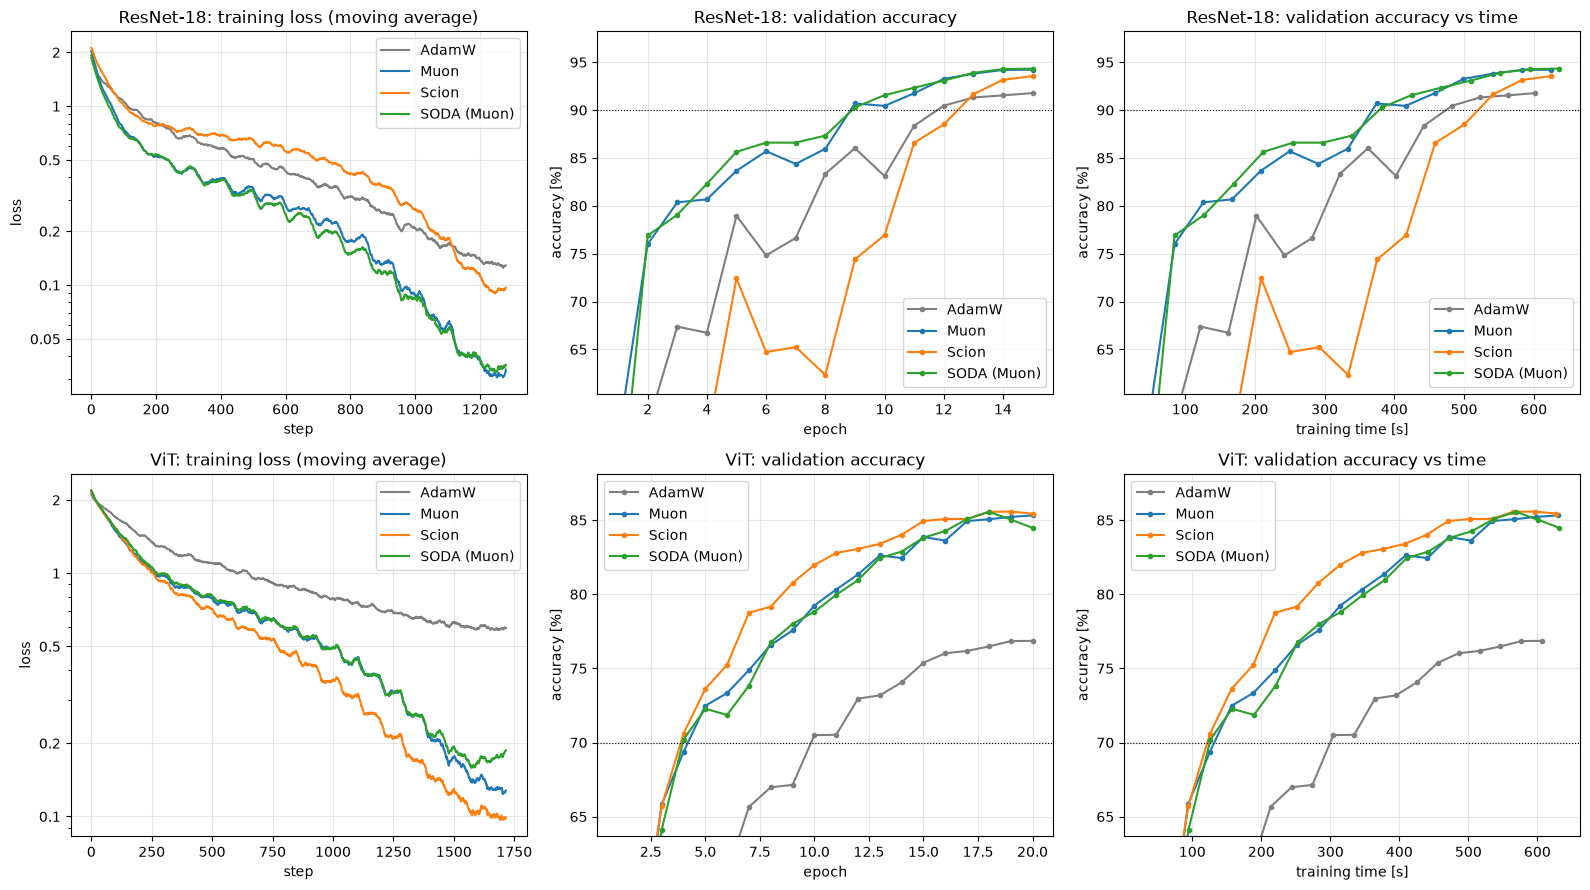

model      optimizer     test acc  best val  final train  s/epoch  epochs to  time to   largest
                              [%]       [%]         loss              target   target  val drop
-----------------------------------------------------------------------------------------------
ResNet-18  AdamW            90.92     91.78       0.1315     40.2         12     483s      4.14
ResNet-18  Muon             93.31     94.22       0.0326     41.7          9     375s      1.32
ResNet-18  Scion            93.11     93.56       0.0957     41.7         13     542s      7.70
ResNet-18  SODA (Muon)      93.22     94.34       0.0347     42.4          9     382s      0.00
(target validation accuracy for ResNet-18: 90%)
ViT        AdamW            76.39     76.86       0.5901     30.3         10     304s      0.00
ViT        Muon             85.75     85.32       0.1292     31.5          5     157s      0.24
ViT        Scion            85.66     85.58       0.0994     31.4          4     126s   

In [11]:
# FILL: plot the results and produce a summary table.
from matplotlib.ticker import FormatStrFormatter, LogLocator, NullFormatter

COLORS = {"AdamW": "tab:gray", "Muon": "tab:blue", "Scion": "tab:orange", "SODA (Muon)": "tab:green"}
TARGETS = {"ResNet-18": 0.90, "ViT": 0.70}  # validation accuracy used for the time-to-accuracy metric


def smooth(x, window=25):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(window) / window, mode="valid")


fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for row, model_name in enumerate(MODELS):
    for opt_name in OPTIMIZERS[model_name]:
        h = results[model_name, opt_name]
        c = COLORS.get(opt_name)
        axes[row, 0].plot(smooth(h["step_loss"]), color=c, label=opt_name)
        axes[row, 1].plot(h["epoch"], 100 * np.array(h["val_acc"]), "o-", ms=3, color=c, label=opt_name)
        axes[row, 2].plot(h["time"], 100 * np.array(h["val_acc"]), "o-", ms=3, color=c, label=opt_name)
    axes[row, 0].set(title=f"{model_name}: training loss (moving average)", xlabel="step", ylabel="loss", yscale="log")
    axes[row, 0].yaxis.set_major_locator(LogLocator(subs=(1.0, 2.0, 5.0)))
    axes[row, 0].yaxis.set_major_formatter(FormatStrFormatter("%g"))
    axes[row, 0].yaxis.set_minor_formatter(NullFormatter())
    axes[row, 1].set(title=f"{model_name}: validation accuracy", xlabel="epoch", ylabel="accuracy [%]")
    axes[row, 2].set(title=f"{model_name}: validation accuracy vs time", xlabel="training time [s]", ylabel="accuracy [%]")
    lo = min(100 * min(results[model_name, o]["val_acc"][len(results[model_name, o]["val_acc"]) // 3:]) for o in OPTIMIZERS[model_name])
    for ax in axes[row, 1:]:
        ax.set_ylim(lo - 2, None)
        ax.axhline(100 * TARGETS[model_name], color="k", lw=0.8, ls=":")
    for ax in axes[row]:
        ax.grid(alpha=0.3)
        ax.legend()
plt.tight_layout()
plt.show()


def time_to(h, target):
    for epoch, t, acc in zip(h["epoch"], h["time"], h["val_acc"]):
        if acc >= target:
            return epoch, t
    return None, None


def largest_val_drop(h):
    """Largest decrease of the validation accuracy from one epoch to the next, in points (0 if it never decreased)."""
    acc = 100 * np.array(h["val_acc"])
    return float(np.max(np.maximum(acc[:-1] - acc[1:], 0), initial=0))


header = (f"{'model':10s} {'optimizer':12s} {'test acc':>9s} {'best val':>9s} {'final train':>12s} {'s/epoch':>8s}"
          f" {'epochs to':>10s} {'time to':>8s} {'largest':>9s}")
print(header)
print(f"{'':10s} {'':12s} {'[%]':>9s} {'[%]':>9s} {'loss':>12s} {'':>8s} {'target':>10s} {'target':>8s} {'val drop':>9s}")
print("-" * len(header))
for model_name in MODELS:
    for opt_name in OPTIMIZERS[model_name]:
        h = results[model_name, opt_name]
        ep, t = time_to(h, TARGETS[model_name])
        print(f"{model_name:10s} {opt_name:12s} {100 * h['test_acc']:9.2f} {100 * max(h['val_acc']):9.2f}"
              f" {h['train_loss'][-1]:12.4f} {h['time'][-1] / len(h['epoch']):8.1f}"
              f" {ep if ep else '-':>10} {f'{t:.0f}s' if t else '-':>8s} {largest_val_drop(h):9.2f}")
    print(f"(target validation accuracy for {model_name}: {100 * TARGETS[model_name]:.0f}%)")

## Discussion

*Write your answer here.*

We trained a ResNet-18 with 11.2M parameters and a small Vision Transformer with 3.2M parameters on CIFAR-10. The ViT cuts the image into 4×4 patches and uses 6 pre-norm blocks of width 256 with 8 heads, followed by a mean pooling over the tokens. We kept 5000 training images aside as a validation set and used the test set only for the final accuracy. To make the comparison fair, every run starts from the same initialization and sees the same batches, with batch size 512, random crops and flips, bf16 autocast and a linear warmup followed by a cosine decay to zero. The ResNet is trained for 15 epochs and the ViT for 20. This is short, but our only GPU was the integrated Intel Arc GPU of a laptop, used through the XPU backend of PyTorch, and one epoch already takes about 40 s for the ResNet and 30 s for the ViT.

Muon and SODA follow the reference implementations, so only the hidden weight matrices are updated with Muon, while the first layer, the classifier and all gains and biases use AdamW. For SODA we wrapped Muon, since it was the strongest base optimizer in our first runs, and we turned off all its weight decay as the paper asks. Scion uses the spectral norm for the convolutional and linear layers, the sign geometry for the classifier and an RMS normalization for the vectors. We started from the radii of the official examples, which are 8 for the hidden layers and 128 for the classifier in the CIFAR network, and 25 and 500 in DeiT.

Since these optimizers work at very different scales, we first tuned each of them on shorter runs, 5 epochs for the ResNet and 10 for the ViT, with a learning rate grid where every value is twice the previous one. The tables give the validation accuracy in % at the end of these runs.

ResNet-18, 5 epochs:

| Optimizer | learning rate: validation accuracy |
|---|---|
| AdamW (wd 0.05) | 0.001: 81.7, 0.002: 83.2, 0.004: 83.5, 0.008: 80.6 |
| Muon (no wd) | 0.01: 86.1, 0.02: 88.7, 0.04: 90.1, 0.08: 89.8, 0.16: 90.0 |
| Scion, official radii | 0.003: 81.9, 0.006: 86.4, 0.0125: 87.8, 0.025: 86.4, 0.05: 75.0, 0.1: 55.0 |
| Scion, vector radius 1 | 0.0125: 90.1, 0.025: 88.3 |
| SODA (Muon) | 0.01: 79.5, 0.02: 86.2, 0.04: 88.6, 0.08: 90.0, 0.16: 90.1 |

With a fixed learning rate we also tuned the weight decay: for AdamW (lr 0.003) wd 0.05, 0.2, 0.5 and 1 gave 83.2, 83.7, 84.1 and 84.0, and for Muon (lr 0.04) wd 0, 0.01, 0.05 and 0.1 gave 90.1, 89.4, 90.0 and 90.7.

ViT, 10 epochs:

| Optimizer | warmup of 0.5 epoch | warmup of 2 epochs |
|---|---|---|
| AdamW (wd 0.05) | 0.00025: 67.7, 0.0005: 69.5, 0.001: 67.6, 0.002: 60.9, 0.004: 53.0 | 0.0005: 70.5, 0.001: 70.0, 0.002: 65.4 |
| Muon (no wd) | 0.0025: 78.1, 0.005: 80.8, 0.01: 80.6, 0.02: 74.1, 0.04: 61.5, 0.08: 42.3 | 0.005: 81.0, 0.01: 81.5, 0.02: 75.8 |
| Scion, official radii | 0.0001: 74.7, 0.0002: 76.1, 0.0004: 74.9, 0.0008: 70.9, 0.0016: 48.1, 0.0032: 32.2 | 0.0004: 76.5, 0.0008: 71.2 |
| Scion, vector radius 1 | | 0.0002: 81.1, 0.0004: 83.2, 0.0008: 82.1 |
| SODA (Muon) | 0.01: 79.7, 0.02: 78.9, 0.04: 69.7, 0.08: 58.1 | 0.01: 81.2, 0.02: 79.8 |

Here the weight decay mattered for Muon, where wd 0, 0.05 and 0.2 gave 81.5, 81.5 and 82.2, but not for AdamW, which stayed between 70.0 and 70.6 for wd between 0.05 and 0.5.

These sweeps changed our setup in three ways. First, with the official radii Scion was clearly behind Muon on both models. The problem was the group of vectors: Scion moves the gains, biases and the positional embedding by an RMS-normalized step of size lr × radius, so with radius 8 the BatchNorm gains of the ResNet changed by about 0.1 at every step, many times more than with Adam. The official examples do not have this problem because the CIFAR network keeps its BatchNorm weights frozen and the DeiT model uses RMSNorm without weights, while our models train these gains. Giving the vectors their own radius of 1 brought Scion from 87.8% to 90.1% on the ResNet and from 76.5% to 83.2% on the ViT, so these radii really have to be adapted to the architecture. Second, the ViT was much more sensitive to the learning rate than the ResNet for every optimizer, and half an epoch of warmup was not enough. With 2 epochs of warmup all optimizers gained about one point and tolerated larger learning rates, so we used a 2-epoch warmup for the ViT in the final runs. We also tried a LayerNorm on the queries and keys, but it only helped AdamW by about one point at the larger learning rate and made the epochs about 40% slower, so we kept the plain ViT. Third, SODA did not keep the optimal learning rate of Muon, which we discuss below.

The final runs are shown in the figure and the table above. On the ResNet, the three new optimizers end clearly above AdamW: Muon reaches 93.3% test accuracy, SODA 93.2% and Scion 93.1%, against 90.9% for AdamW. They also fit the training data much better, with a final training loss of 0.03 for Muon and SODA, 0.10 for Scion and 0.13 for AdamW. Muon and SODA are also the fastest, as both reach 90% validation accuracy after 9 epochs, while AdamW needs 12 and Scion 13. On the ViT the gap with AdamW is even larger: Muon reaches 85.8%, Scion 85.7% and SODA 84.1%, against 76.4% for AdamW. Here Scion and SODA reach 70% after 4 epochs, Muon after 5 and AdamW after 10, and Scion stays slightly ahead of Muon in validation accuracy during almost the whole training. An epoch takes almost the same time with every optimizer, between 40.2 and 42.4 s for the ResNet and between 30.3 and 31.6 s for the ViT, so the orthogonalization only costs a few percent and the ranking in wall-clock time is the same as in epochs. For example, Muon needs about 160 s of training to reach 70% on the ViT, where AdamW needs about 300 s.

None of the final runs diverged and all training losses decrease smoothly, but the validation curves are quite different. On the ResNet, the validation accuracy of AdamW and especially of Scion jumps a lot during the first two thirds of the training. For example, Scion falls from 72.4% to 64.7% between epochs 5 and 6 and is still at 62.3% at epoch 8, while its training loss keeps decreasing. This only happens in evaluation mode, so we think that the BatchNorm running statistics cannot follow the weights when they move fast, and the curves settle once the learning rate decays. The last column of the table measures this: the largest drop between two epochs is 7.7 points for Scion and 4.1 for AdamW, against 1.3 for Muon and none for SODA. On the ViT all validation curves are smooth, except at the end for SODA, which we explain below. The sweeps also show how sensitive each method is to the learning rate. On the ResNet, Muon gave the same accuracy for every learning rate between 0.04 and 0.16, while Scion and AdamW lost one to three points when we doubled their best learning rate. On the ViT, every optimizer became unstable when the learning rate was too large, with the training loss going up again after a few epochs, for example from 1.61 to 1.78 between epochs 2 and 4 for Muon with lr 0.08, and SODA was the most tolerant there.

SODA was the most surprising of the four. With the learning rate of Muon it was clearly worse on the ResNet, for example 79.5% against 86.1% at lr 0.01, and it needed a learning rate two to four times larger to reach the same accuracy. We think this is because the pull towards the initialization removes part of every past update. Writing $\Delta_j$ for the base update at step $j$, after $K$ steps the distance to the initialization is $\sum_{j<K}\frac{j+1}{K+1}\Delta_j$ instead of $\sum_{j<K}\Delta_j$, so the updates of the first half of training count with a weight below $1/2$, and a larger base learning rate compensates for this. A second effect comes from the schedule. The decay $1/(k+2)$ is not multiplied by the learning rate, so at the end of the cosine schedule, when the base step goes to zero, the weights keep moving back towards the initialization. With a small learning rate this was clearly visible: with lr 0.01 the validation accuracy dropped in the last epoch from 81.5% to 79.5% on the ResNet and from 81.5% to 79.7% on the ViT. Since the $1/k$ averaging is close to the idea behind schedule-free methods, we also tried SODA with a constant learning rate after the warmup, but on the ViT this gave only 77.6% and 76.3%. On the other hand, SODA made the ViT much more robust to large learning rates: at lr 0.02 it reached 78.9% where Muon reached 74.1%, and at 0.04 it reached 69.7% against 61.5%. Pulling the weights back seems to stop them from growing too fast, which is what made Muon unstable there. Wrapping AdamW or unconstrained Scion with the learning rate of the base optimizer also made them worse, with 82.7% against 83.2% to 84.1% for AdamW and 80.3% against 85.2% for unconstrained Scion, which again shows that the learning rate has to be tuned again. In the final runs, SODA without weight decay reached 93.2% on the ResNet, about the same as the 93.3% of Muon with a tuned weight decay. On the ViT it ended at 84.1% against 85.8%, but its best validation accuracy, 85.6% at epoch 18, was as high as the one of Scion, and it lost 1.1 points in the last two epochs, which is again the pull towards the initialization at the end of the schedule. So in our multi-epoch setting SODA removes the weight decay as a hyperparameter, but not the tuning. This agrees with the paper, which says that the method was designed for single-epoch training and that multi-epoch training may need an extra regularization parameter.

The speed of Muon and Scion comes from the shape of their updates. Adam normalizes every coordinate separately, while Muon and Scion replace the momentum of a weight matrix by its orthogonal factor $UV^\top$, so all singular directions of the update move by the same amount. Directions with a small gradient, which Adam would barely change, get the same step as the dominant ones, and the size of the step is measured in the spectral norm, which controls how much the output of the layer can change. Each step therefore makes more progress, which matters most in short trainings like ours, and the cost of the five Newton-Schulz iterations is small compared to the forward and backward passes, so an epoch takes about the same time for all optimizers. Scion goes one step further by choosing a norm for every kind of layer and keeping the weights inside a ball of a given radius, which is also why it was the most sensitive to the choice of these radii.

Our conclusions have some limits. Every final run uses a single seed. Running the whole notebook twice with the same seed changed the test accuracies by up to 0.4 points and the number of epochs to the target by one, because some GPU kernels are not deterministic, so smaller differences should not be taken too seriously. In particular, Muon, SODA and Scion are tied on the ResNet, and so are Muon and Scion on the ViT. The trainings are short and the learning rates were tuned on even shorter runs, so with longer trainings the ranking could change, especially for AdamW, which is still far from convergence on the ViT. Finally, the timings were measured on an integrated GPU, and on other hardware the relative cost of the Newton-Schulz iterations could be different.

## Reflection on AI-assisted coding

*Write your answer here.*

Having AI tools to help us write the code and set up the experiments changed how we spent our time on this homework. Instead of spending most of it writing code, we had more time to interpret the results and to understand where they come from and how the optimizers differ from each other. We believe this allowed us to get a good practical view of what we saw in the lectures without having to sink a lot of time into it.